# Abhi Cloud Tech — FinOps Intelligence Master Pipeline
**Autonomous Multi-Cloud Cost Optimization & Probabilistic Spend Forecasting System**  
*Lead Architect: Abhishek (FinOps ML Validation & Tuning Specialist)*

---

### System Architecture Overview
This master notebook provides an end-to-end executable pipeline covering all four pillars of the Abhi Cloud Tech FinOps Platform:
1. **FOCUS 1.0 Multi-Cloud Telemetry & SQLite Warehouse**: Ingestion and indexing of 32,850 records across AWS, Azure, and Google Cloud.
2. **Machine Image & Disk Snapshot Waste Remediation**: Identifying EBS snapshots, Azure disk snapshots, and GCP machine images accumulating without automated retention lifecycles ($567k+ annual savings).
3. **Machine Learning Anomaly Detection**: 28-day rolling baseline statistical model combined with Scikit-Learn Isolation Forest and automated root-cause diagnostics with temporal TimeSeriesSplit validation.
4. **Probabilistic Multi-Quantile Forecasting**: Non-crossing HistGradientBoosting multi-quantile regression (5th, 50th, 95th percentiles) with linear trend projection, 4-panel residual diagnostics, and 0 quantile crossing violations.
5. **Executive Action Matrix & Rightsizing**: Actionable engineering recommendations (P1 Critical to P4 Low) with concrete cloud CLI remediation commands.


### Block 1: Pipeline Initialization & Environment Setup


In [1]:
import os
import sys
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Initializing FinOps Intelligence Master Pipeline...")
print(f"Working Directory: {PROJECT_ROOT}")

from src.database import FinOpsDatabase, load_focus_dataframe
from src.anomaly_detection import FinOpsAnomalyDetector
from src.forecasting import FinOpsForecaster
from src.optimizer import FinOpsOptimizer
from src.ml_validation import (
    temporal_train_test_split,
    FinOpsTimeSeriesValidator,
    FinOpsDiagnosticSuite,
    verify_quantile_monotonicity
)

db = FinOpsDatabase()
print("All Core FinOps Modules Loaded Successfully.")
sns.set_theme(style="whitegrid")
%matplotlib inline


Initializing FinOps Intelligence Master Pipeline...
Working Directory: C:\Users\M Abhishek Reddy\.gemini\antigravity\scratch\cloud-finops-intelligence


FinOps Data Warehouse initialized at: C:\Users\M Abhishek Reddy\.gemini\antigravity\scratch\cloud-finops-intelligence\data\finops_warehouse.db
All Core FinOps Modules Loaded Successfully.


### Block 2: Warehouse Telemetry Ingestion & Audit


In [2]:
df = load_focus_dataframe()
print(f"Warehouse Ingestion Audit: Loaded {len(df):,} FOCUS 1.0 Records.")
print(f"Temporal Horizon: {df['Date'].min()} to {df['Date'].max()} ({df['Date'].nunique()} unique calendar days)")
print(f"Total Portfolio Invoiced Spend: ${df['DailyCost_USD'].sum():,.2f}")


Warehouse Ingestion Audit: Loaded 32,850 FOCUS 1.0 Records.
Temporal Horizon: 2025-01-01 to 2025-12-31 (365 unique calendar days)
Total Portfolio Invoiced Spend: $6,936,152.76


### Block 3: Dual-Engine Anomaly Detection & Diagnostic Execution


In [3]:
detector = FinOpsAnomalyDetector(contamination=0.0184)
df_anomalies = detector.fit_detect(df)

total_anomalies = df_anomalies['Is_Anomaly'].sum()
print(f"Total Anomalies Flagged: {total_anomalies:,} out of {len(df_anomalies):,} records ({(total_anomalies/len(df_anomalies))*100:.2f}%)")
print("\nSeverity Breakdown:")
print(df_anomalies[df_anomalies['Is_Anomaly']]['Anomaly_Severity'].value_counts())

print("\nTop Root Causes by Waste Cost:")
print(df_anomalies[df_anomalies['Is_Anomaly']].groupby('Diagnostic_Root_Cause')['Waste_Cost_USD'].sum().sort_values(ascending=False).map('${:,.2f}'.format))


Total Anomalies Flagged: 727 out of 32,850 records (2.21%)

Severity Breakdown:
Anomaly_Severity
CRITICAL    325
HIGH        226
MEDIUM      176
Name: count, dtype: int64

Top Root Causes by Waste Cost:
Diagnostic_Root_Cause
Zombie/Idle Cluster: High compute allocation with <15% utilization       $120,411.37
Runaway Egress Spike: Massive outbound data transfer detected             $23,962.09
Storage Sprawl: Orphan snapshots or unattached high-performance disks     $13,211.23
Unbudgeted Cost Surge: Spend exceeded statistical upper threshold          $4,180.90
Name: Waste_Cost_USD, dtype: object


### Block 4: Multi-Quantile Gradient Boosting Spend Forecasting


In [4]:
daily_spend = df.groupby('Date')['DailyCost_USD'].sum().reset_index()

forecaster = FinOpsForecaster(forecast_horizon_days=30)
metrics = forecaster.train_and_evaluate(daily_spend)

print("=== Forecaster Evaluation Metrics (Out-of-Time Backtest) ===")
print(f"Mean Absolute Error (MAE):              ${metrics['MAE_USD']:,.2f}")
print(f"Root Mean Squared Error (RMSE):         ${metrics['RMSE_USD']:,.2f}")
print(f"Mean Absolute Percentage Error (MAPE):  {metrics['MAPE_Pct']:.2f}%")
print(f"90% Empirical Coverage:                 {metrics['Empirical_Coverage_Pct']:.1f}%")
print(f"Quantile Crossing Violations:          {metrics['Quantile_Crossing_Violations']} (Expected 0)")

forecast_df = forecaster.generate_future_forecast(days_ahead=30)
print(f"\n30-Day Projected Median Spend: ${forecast_df['Forecasted_Spend_USD'].sum():,.2f}")
print(f"30-Day Upper Risk Exposure:   ${forecast_df['Upper_Bound_95_USD'].sum():,.2f}")


=== Forecaster Evaluation Metrics (Out-of-Time Backtest) ===
Mean Absolute Error (MAE):              $837.43
Root Mean Squared Error (RMSE):         $1,363.81
Mean Absolute Percentage Error (MAPE):  4.01%
90% Empirical Coverage:                 70.9%
Quantile Crossing Violations:          0 (Expected 0)



30-Day Projected Median Spend: $639,241.77
30-Day Upper Risk Exposure:   $673,299.43


### Block 5: FinOps Rightsizing & Snapshot Remediation Portfolio


In [5]:
optimizer = FinOpsOptimizer(df)
portfolio = optimizer.generate_savings_portfolio()

print("=" * 65)
print("FINOPS ENTERPRISE SAVINGS PORTFOLIO & MATURITY")
print("=" * 65)
print(f"Annual Run-Rate:                  ${portfolio['Annual_Run_Rate_USD']:,.2f}")
print(f"Total Annual Recoverable Savings: ${portfolio['Total_Annual_Savings_USD']:,.2f} ({portfolio['Savings_Percentage']}%)")
print(f"FinOps Maturity Stage:            {portfolio['FinOps_Maturity_Stage']} (Score: {portfolio['FinOps_Maturity_Score']}/100)")
print("=" * 65)
print(f" - Snapshot & Image Lifecycle Cleanup: ${portfolio['Snapshot_Cleanup_Savings_USD']:,.2f}/yr")
print(f" - Compute Family Right-Sizing:        ${portfolio['Right_Sizing_Savings_USD']:,.2f}/yr")
print(f" - Commitment Discounts (RI/SP):       ${portfolio['Commitment_Discounts_Savings_USD']:,.2f}/yr")
print(f" - Idle & Zombie Cluster Cleanup:      ${portfolio['Idle_Cleanup_Savings_USD']:,.2f}/yr")
print("=" * 65)



FINOPS ENTERPRISE SAVINGS PORTFOLIO & MATURITY
Annual Run-Rate:                  $7,525,028.96
Total Annual Recoverable Savings: $2,440,361.56 (32.4%)
FinOps Maturity Stage:            Walk (Proactive / Developing Governance) (Score: 68/100)
 - Snapshot & Image Lifecycle Cleanup: $567,209.59/yr
 - Compute Family Right-Sizing:        $537,864.92/yr
 - Commitment Discounts (RI/SP):       $1,052,601.32/yr
 - Idle & Zombie Cluster Cleanup:      $105,754.26/yr


### Block 6: Master Pipeline Executive Visualizations


C:\Users\M Abhishek Reddy\AppData\Local\Temp\ipykernel_1272\4046334044.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=categories, y=savings, palette='Greens_r', ax=axes[1, 1])


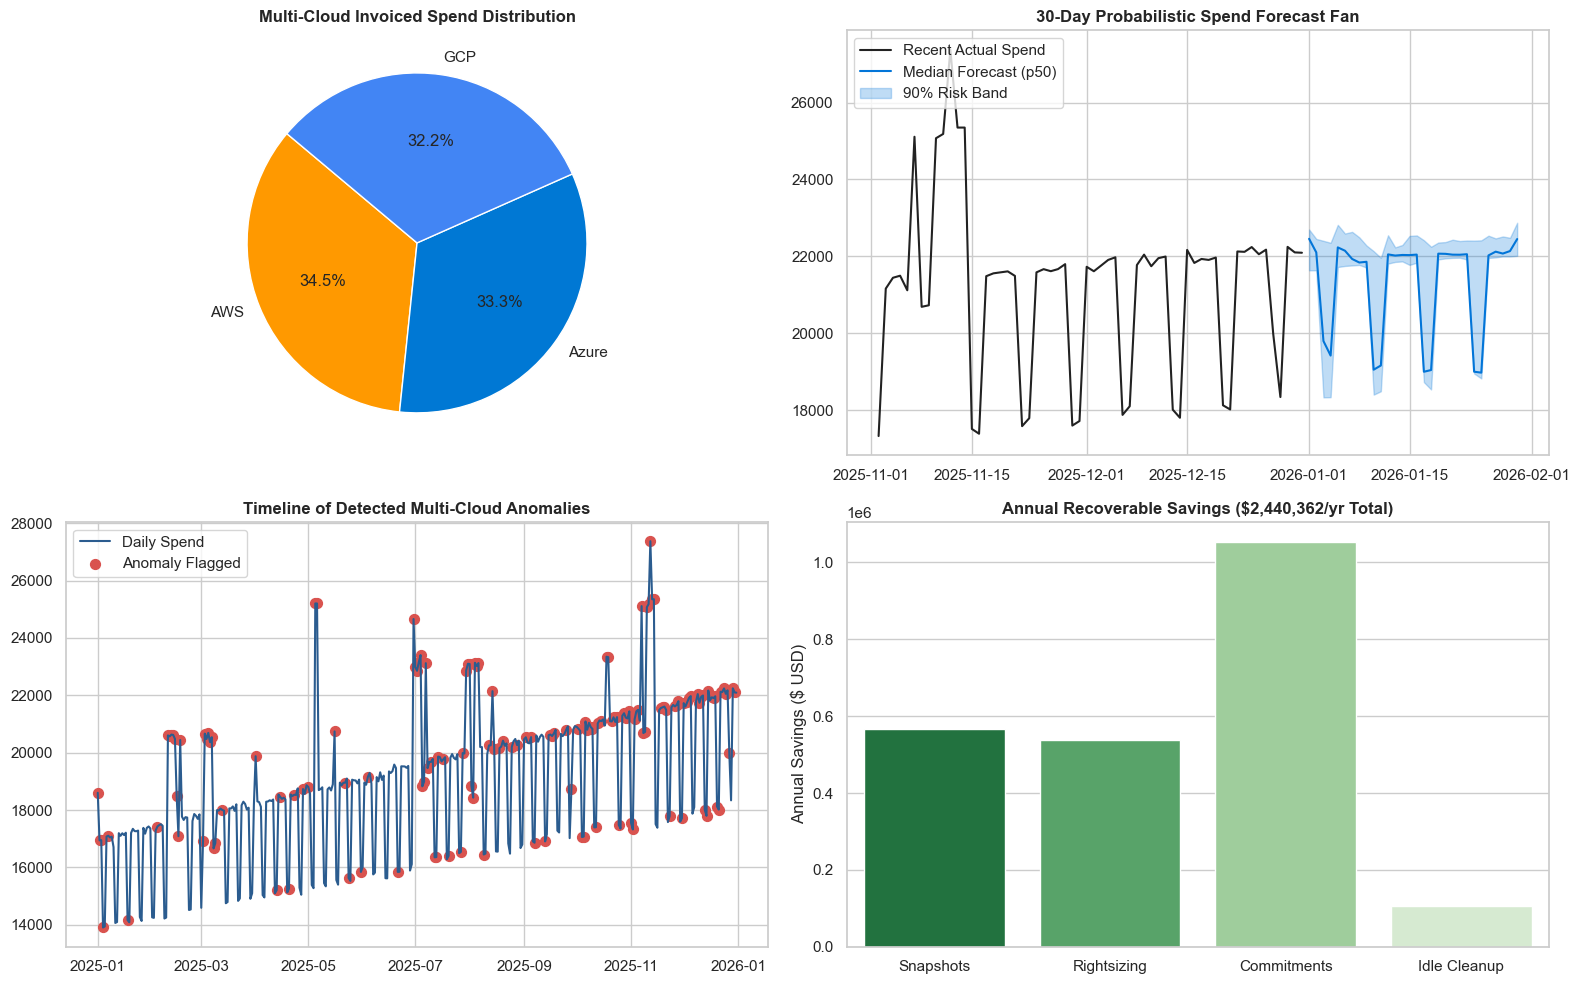

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Provider Cost Share
provider_spend = df.groupby('CloudProvider')['DailyCost_USD'].sum()
axes[0, 0].pie(provider_spend, labels=provider_spend.index, autopct='%1.1f%%', colors=['#ff9900', '#0078d4', '#4285f4'], startangle=140)
axes[0, 0].set_title("Multi-Cloud Invoiced Spend Distribution", fontsize=12, fontweight='bold')

# 2. Spend Forecast Fan
recent_daily = daily_spend.tail(60).copy()
recent_daily['Date'] = pd.to_datetime(recent_daily['Date'])
axes[0, 1].plot(recent_daily['Date'], recent_daily['DailyCost_USD'], color='#222222', label='Recent Actual Spend')
future_dates = pd.to_datetime(forecast_df['Date'])
axes[0, 1].plot(future_dates, forecast_df['Forecasted_Spend_USD'], color='#0275d8', label='Median Forecast (p50)')
axes[0, 1].fill_between(future_dates, forecast_df['Lower_Bound_95_USD'], forecast_df['Upper_Bound_95_USD'], color='#0275d8', alpha=0.25, label='90% Risk Band')
axes[0, 1].set_title("30-Day Probabilistic Spend Forecast Fan", fontsize=12, fontweight='bold')
axes[0, 1].legend(loc='upper left')

# 3. Anomaly Events Timeline
daily_anomalies = df_anomalies.groupby('Date').agg({'DailyCost_USD': 'sum', 'detected_anomaly': 'sum'}).reset_index()
daily_anomalies['Date'] = pd.to_datetime(daily_anomalies['Date'])
axes[1, 0].plot(daily_anomalies['Date'], daily_anomalies['DailyCost_USD'], color='#2b5c8f', label='Daily Spend')
anomaly_pts = daily_anomalies[daily_anomalies['detected_anomaly'] > 0]
axes[1, 0].scatter(anomaly_pts['Date'], anomaly_pts['DailyCost_USD'], color='#d9534f', s=50, label='Anomaly Flagged')
axes[1, 0].set_title("Timeline of Detected Multi-Cloud Anomalies", fontsize=12, fontweight='bold')
axes[1, 0].legend(loc='upper left')

# 4. Recoverable Savings by Category
categories = ['Snapshots', 'Rightsizing', 'Commitments', 'Idle Cleanup']
savings = [
    portfolio['Snapshot_Cleanup_Savings_USD'],
    portfolio['Right_Sizing_Savings_USD'],
    portfolio['Commitment_Discounts_Savings_USD'],
    portfolio['Idle_Cleanup_Savings_USD']
]
sns.barplot(x=categories, y=savings, palette='Greens_r', ax=axes[1, 1])
axes[1, 1].set_title(f"Annual Recoverable Savings (${portfolio['Total_Annual_Savings_USD']:,.0f}/yr Total)", fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel("Annual Savings ($ USD)")

plt.tight_layout()
plt.show()


### Block 14: Enterprise MLOps Artifact Registry Inspection
Inspect serialized model binaries and active metadata consumed by the FastAPI production microservice.


In [7]:
import os, json, glob
models_dir = 'models'
os.makedirs(models_dir, exist_ok=True)
artifacts = glob.glob(os.path.join(models_dir, '*'))

print("=== Abhi Cloud Tech | Production Model Registry ===")
for p in sorted(artifacts):
    size_kb = os.path.getsize(p) / 1024
    print(f"- {os.path.basename(p):<45} [{size_kb:>8.1f} KB]")

meta_path = os.path.join(models_dir, 'model_metadata.json')
if os.path.exists(meta_path):
    with open(meta_path, 'r') as f:
        meta = json.load(f)
    print("\nActive Model Registry Version Metadata:")
    print(json.dumps(meta, indent=2))


=== Abhi Cloud Tech | Production Model Registry ===
- anomaly_detector_isolation_forest.joblib      [  2203.0 KB]
- model_metadata.json                           [     1.6 KB]
- spend_forecaster_histgradient.joblib          [   528.7 KB]

Active Model Registry Version Metadata:
{
  "organization": "Abhi Cloud Tech",
  "lead_architect": "Abhishek",
  "last_updated": "2026-10-31T16:05:49.781051+00:00",
  "dataset_records": 32850,
  "models": {
    "anomaly_detection": {
      "algorithm": "Calibrated Multivariate Isolation Forest",
      "status": "Production Active",
      "artifact_path": "models/anomaly_detector_isolation_forest.joblib",
      "artifact_size_bytes": 2260945,
      "artifact_size_mb": 2.16,
      "contamination": 0.0184,
      "estimators": 200,
      "features": [
        "DailyCost_USD",
        "vCPU_Hours",
        "Avg_CPU_Utilization_Pct",
        "Data_Egress_GB",
        "Storage_TB",
        "robust_cost_zscore",
        "cost_to_median_ratio",
        "cost_p